In [1]:
import lightning.pytorch as pl
from lightning.pytorch.callbacks.early_stopping import EarlyStopping
import numpy as np
import pandas as pd
import wandb
import torch

from lightning.pytorch.loggers import WandbLogger

from doubleml_deep import DoubleMLLightning
from doubleml_deep import DoubleMLDeepData
from doubleml_deep.plr import DoubleMLPLRDeep

from doubleml_deep.default_models import (
    DoubleMLDeepDistilBertModel,
    DoubleMLDeepBertModel,
    DoubleMLDeepBeitModel,
    DoubleMLDeepTabTransformerModel,
    DoubleMLDeepSaintModel,
    DoubleMLDeepVitModel,
)

from doubleml import DoubleMLData, DoubleMLPLR
from doubleml.utils import dummy_regressor
from lightgbm import LGBMRegressor
from sklearn.base import clone
from sklearn.dummy import DummyRegressor

2023-10-02 07:13:37.272914: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-10-02 07:13:39.093910: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [18]:
import os

logging_project = "DoublemlDeep_Presentation"
rootpath = "/home/container/"
os.chdir(rootpath)
csv_path = "data/datasets/data_tab_masterthesis_jan.csv"
img_folder_path = "data/datasets/image_toys_data/"

# Model parameters
score = "partialling out"
data_field_map = {
    "outcome": ["ln_q"],
    "treatments": ["ln_p"],
    "tab_cols": {"cat_cols": [], "con_cols": ["Reviews: Rating", 
                                              "Reviews: Review Count", 
                                              "New Offer Count: Current", 
                                              "Count of retrieved live offers: New, FBA", 
                                              "Count of retrieved live offers: New, FBM"]},
    "txt_cols": ["text"],
    "img_cols": ["img0"],
}
fusion_head = [768]
embedding_dim = 1536

# training params
n_epochs = 8
train_val_test_split = {"train": 0.70, "validation": 0.25, "test": 0.01}
batch_size = 8
num_workers = 2
precision = "16-mixed"
gradient_clip_val = 1
accumulate_grad_batches = 4
scheduler = "ReduceLROnPlateau"
patience = 3
embedding_dropout = 0.1
freeze_img_model = False
freeze_txt_model = False

# optimizer and scheduler
optim = "AdamW"
lr = 3e-5
momentum = 0.95
weight_decay = 0.0001

In [4]:
data_field_map

{'outcome': ['ln_q'],
 'treatments': ['ln_p'],
 'tab_cols': {'cat_cols': [],
  'con_cols': ['Reviews: Rating',
   'Reviews: Review Count',
   'New Offer Count: Current',
   'Count of retrieved live offers: New, FBA',
   'Count of retrieved live offers: New, FBM']},
 'txt_cols': ['text'],
 'img_cols': ['img0']}

In [19]:
txtm = DoubleMLDeepBertModel(padding=True)
imgm = DoubleMLDeepBeitModel()
tabm = DoubleMLDeepTabTransformerModel(tab_cols=data_field_map["tab_cols"], cat_embed_input=[])

Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertModel: ['cls.predictions.transform.dense.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.seq_relationship.bias', 'cls.predictions.transform.dense.bias', 'cls.predictions.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of the model checkpoint at microsoft/beit-base-patch16-224-pt22k-ft22k were not used when initializing BeitModel: ['classifier.bias', 'classifier.weight']
- This IS expected if

In [15]:
model_dict = {"txt": txtm, 
              "img": imgm, 
              "tab": None}

In [16]:
# Training parameters
early_stopping_callback = EarlyStopping(monitor="val_combined_loss",
                                        min_delta=0.001,
                                        patience=patience,
                                        verbose=False,
                                        mode="min")

In [20]:
# Set up modules and models
data_module = DoubleMLDeepData(
    csv_path=csv_path,
    image_dir=img_folder_path,
    data_field_map=data_field_map,
    model_dict=model_dict,
    train_val_test_split=train_val_test_split,
    num_workers=num_workers,
    batch_size=batch_size,
)
model = DoubleMLPLRDeep(
    data_field_map=data_field_map,
    model_dict=model_dict,
    fusion_head=fusion_head,
    embedding_dim=embedding_dim,
    score=score,
    freeze_img_model=freeze_img_model,
    freeze_txt_model=freeze_txt_model,
    embedding_dropout=embedding_dropout,
)
lightning_model = DoubleMLLightning(
    doubleml_model=model,
    optim=optim, lr=lr,
    momentum=momentum,
    weight_decay=weight_decay,
    scheduler=scheduler,
    save_hyperparameters=True
)

In [9]:
import wandb
def set_up_logging():
    # set up logging
    wandb.login()
    wandb_logger = WandbLogger(
        project=logging_project,
    )

    # Log parameters
    wandb.log({"dataset_csv": csv_path})
    wandb.log(train_val_test_split)
    wandb.log({"TxtModel": type(txtm).__name__})
    wandb.log({"ImgModel": type(imgm).__name__})
    wandb.log({"TabModel": type(tabm).__name__})
    wandb.log({"ScoreType": score})

    wandb.log({"num_workers": num_workers})
    wandb.log({"batch_size": batch_size})
    wandb.log({"fusion_head": fusion_head})
    wandb.log({"freeze_img_model": freeze_img_model})
    wandb.log({"freeze_txt_model": freeze_txt_model})
    wandb.log({"optim": optim})
    wandb.log({"lr": lr})
    wandb.log({"precision": precision})
    return wandb_logger


def log_dml_output():
    # without embeddings
    wandb.log({"theta_ln_p": dml_plr_obj.summary["coef"][0]})
    wandb.log({"P>|t|(ln_p)": dml_plr_obj.summary["P>|t|"][0]})
    wandb.log({"CI 2.5 % (ln_p)": dml_plr_obj.summary["2.5 %"][0]})
    wandb.log({"CI 97.5 % (ln_p)": dml_plr_obj.summary["97.5 %"][0]})

    # with embeddings
    wandb.log({"theta_ln_p (embedding)": embed_dml_plr_obj.summary["coef"][0]})
    wandb.log({"P>|t|(ln_p) (embedding)": embed_dml_plr_obj.summary["P>|t|"][0]})
    wandb.log({"CI 2.5 % (ln_p) (embedding)": embed_dml_plr_obj.summary["2.5 %"][0]})
    wandb.log({"CI 97.5 % (ln_p) (embedding)": embed_dml_plr_obj.summary["97.5 %"][0]})

    wandb.finish()
    return


In [21]:
wandb_logger = set_up_logging()

wandb: WARNING Calling wandb.login() after wandb.init() has no effect.
/home/container/.local/lib/python3.11/site-packages/lightning/pytorch/loggers/wandb.py:396: UserWarning: There is a wandb run already in progress and newly created instances of `WandbLogger` will reuse this run. If this is not desired, call `wandb.finish()` before instantiating `WandbLogger`.
  rank_zero_warn(


In [22]:
trainer = pl.Trainer(
            max_epochs=n_epochs,
            devices="auto",
            enable_checkpointing=False,
            precision=precision,  # ~ 100% faster than 32
            accelerator="gpu",
            callbacks=[early_stopping_callback],
            gradient_clip_val=gradient_clip_val,
            logger=wandb_logger,
            accumulate_grad_batches=accumulate_grad_batches,
        )

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs


In [ ]:
trainer.fit(lightning_model, data_module)

Found cached dataset csv (/home/container/.cache/huggingface/datasets/csv/default-0088746c6a5abe90/0.0.0/eea64c71ca8b46dd3f537ed218fc9bf495d5707789152eb2764f5c78fa66d59d)


  0%|          | 0/1 [00:00<?, ?it/s]

Found cached dataset csv (/home/container/.cache/huggingface/datasets/csv/default-0088746c6a5abe90/0.0.0/eea64c71ca8b46dd3f537ed218fc9bf495d5707789152eb2764f5c78fa66d59d)


  0%|          | 0/1 [00:00<?, ?it/s]

Map:   0%|          | 0/6444 [00:00<?, ? examples/s]

...

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name          | Type             | Params
---------------------------------------------------
0 | network       | PLRNetwork       | 199 M 
1 | train_metrics | MetricCollection | 0     
2 | val_metrics   | MetricCollection | 0     
3 | test_metrics  | MetricCollection | 0     
---------------------------------------------------
199 M     Trainable params
0         Non-trainable params
199 M     Total params
799.882   Total estimated model params size (MB)


Sanity Checking: 0it [00:00, ?it/s]

Training: 0it [00:00, ?it/s]

Validation: 0it [00:00, ?it/s]

Validation: 0it [00:00, ?it/s]

In [14]:
def convert_pred_to_nparray(predictions, data_module, dml_model):
    # arguments for readability
    # data_module.setup(stage="predict")
    outcome = data_module.data_field_map["outcome"]
    treatments = data_module.data_field_map["treatments"]
    n_treatments = len(treatments)
    emb_dim = dml_model.embedding_dim

    # initialize arrays
    y = np.empty((0, 1))
    d = np.empty((0, n_treatments))
    pred_ml_l = np.empty((0, n_treatments))
    pred_ml_m = np.empty((0, n_treatments))
    embeddings = np.empty((0, emb_dim))
    # tab_feature_names = data_field_map["tab_cols"]["cat_cols"] + data_field_map["tab_cols"]["con_cols"]
    # tab_features = np.empty((0, len(tab_feature_names)))

    # write predictions to arrays
    for idx, batch in enumerate(data_module.predict_dataloader()):
        y = np.row_stack((y, batch[outcome[0]].numpy().reshape(-1, 1)))
        d_matrix = np.column_stack([batch[treatment_name].numpy() for treatment_name in treatments])
        d = np.row_stack((d, d_matrix))
        pred_ml_l = np.row_stack((pred_ml_l, predictions[idx][0].numpy()))
        pred_ml_m = np.row_stack((pred_ml_m, predictions[idx][1].numpy()))
        embeddings = np.row_stack((embeddings, predictions[idx][2].numpy()))
        # tab_features = np.row_stack((tab_features, np.column_stack([batch[key] for key in tab_feature_names])))

    return y, d, pred_ml_l, pred_ml_m, embeddings

In [15]:
predictions = trainer.predict(lightning_model, data_module)

Found cached dataset csv (/home/container/.cache/huggingface/datasets/csv/default-9c6cf66bccf2087f/0.0.0/eea64c71ca8b46dd3f537ed218fc9bf495d5707789152eb2764f5c78fa66d59d)


  0%|          | 0/1 [00:00<?, ?it/s]

Found cached dataset csv (/home/container/.cache/huggingface/datasets/csv/default-9c6cf66bccf2087f/0.0.0/eea64c71ca8b46dd3f537ed218fc9bf495d5707789152eb2764f5c78fa66d59d)


  0%|          | 0/1 [00:00<?, ?it/s]

Map:   0%|          | 0/2301 [00:00<?, ? examples/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Returned Dataloader is equal to valdiation Dataloader!


/home/container/.local/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:432: PossibleUserWarning: The dataloader, predict_dataloader, does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` (try 48 which is the number of cpus on this machine) in the `DataLoader` init to improve performance.
  rank_zero_warn(


Predicting: 0it [00:00, ?it/s]

In [16]:
numpy_predictions = convert_pred_to_nparray(
    predictions=predictions,
    data_module=data_module,
    dml_model=model,
)

Returned Dataloader is equal to valdiation Dataloader!


In [23]:
df.head()

,Unnamed: 0,ln_q,ln_p,0,1,2,3,4,5,6,...,1532,1533,1534,1535,d_ln_p,d_ln_q,d_ln_p_res,d_ln_q_res,ln_q_hat,ln_p_hat
0,0,-11.664556,4.499699,0.000000,0.0,0.0,0.913574,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.257568,1.433122,-0.038255,0.034855,0.171382,-11.835938,4.464844
1,1,-12.542306,3.086030,0.146973,0.0,0.0,0.682617,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.019454,-0.916005,0.015718,0.145194,-12.687500,3.070312
2,2,-12.386835,2.995232,0.000000,0.0,0.0,0.743164,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.030716,-0.071344,-0.760535,-0.178596,-0.332148,-12.054688,3.173828
3,3,-12.783200,2.832625,0.308594,0.0,0.0,0.716309,0.0,0.0,0.0,...,0.0,0.0,0.014542,0.000000,-0.233951,-1.156900,-0.061906,-1.103513,-11.679688,2.894531
4,4,-10.902427,3.295466,0.000000,0.0,0.0,0.773438,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.228890,0.723874,0.459529,-0.035239,-10.867188,2.835938


In [23]:
from sklearn.metrics import r2_score

print(r2_score(numpy_predictions[0], numpy_predictions[2]))
print(r2_score(numpy_predictions[1], numpy_predictions[3]))

0.6072717795549787
0.790828124479181


In [25]:
def estimate_doubleml_plr(numpy_predictions, data_module):
    y, d, pred_ml_l, pred_ml_m, embeddings = numpy_predictions

    outcome = data_module.data_field_map["outcome"][0]
    treatments = data_module.data_field_map["treatments"]
    # tab_feature_names = data_field_map["tab_cols"]["cat_cols"] + data_field_map["tab_cols"]["con_cols"]
    # DoubleMLData with predictions
    data_dict = {outcome: y.reshape(-1), "dummy_covariate": np.zeros(len(y))}
    for i, treatment_name in enumerate(treatments):
        data_dict[treatment_name] = d[:, i]

    dml_df = pd.DataFrame(data_dict)
    obj_dml_data = DoubleMLData(dml_df, y_col=outcome, d_cols=treatments, x_cols=["dummy_covariate"])

    # DoubleMLData with embeddings
    # df_tab = pd.DataFrame(tab_features, columns=tab_feature_names)
    embed_data_dict = {outcome: y.reshape(-1)}
    for i, treatment_name in enumerate(treatments):
        embed_data_dict[treatment_name] = d[:, i]
    df_tab_2 = pd.DataFrame(embed_data_dict)
    embed_dml_df = pd.concat([df_tab_2, pd.DataFrame(embeddings)], axis=1)
    embed_obj_dml_data = DoubleMLData(embed_dml_df, y_col=outcome, d_cols=treatments)

    if score == "IV-type":
        nuisance_name = "ml_g"
    else:
        assert score == "partialling out"
        nuisance_name = "ml_l"

    # DoubleMLPLR with predictions
    pred_dict = {
        treatment_name: {
            nuisance_name: pred_ml_l[:, i].reshape(-1, 1),
            "ml_m": pred_ml_m[:, i].reshape(-1, 1),
        }
        for i, treatment_name in enumerate(treatments)
    }

    ml_l = DummyRegressor(strategy="constant", constant=50)
    ml_m = DummyRegressor(strategy="constant", constant=50)
    dml_plr_obj = DoubleMLPLR(obj_dml_data, ml_l=clone(ml_l), ml_g=clone(ml_l), ml_m=clone(ml_m), score=score)
    dml_plr_obj.fit(external_predictions=pred_dict, store_predictions=True)
    # DoubleMLPLR with embeddings
    embed_ml_l = LGBMRegressor(n_estimators=500, learning_rate=0.02)
    embed_ml_m = LGBMRegressor(n_estimators=500, learning_rate=0.02)
    embed_dml_plr_obj = DoubleMLPLR(embed_obj_dml_data, ml_l=clone(embed_ml_l), ml_g=clone(embed_ml_l), ml_m=clone(embed_ml_m), score=score)
    embed_dml_plr_obj.fit(store_predictions=True)

    return obj_dml_data, embed_obj_dml_data, dml_plr_obj, embed_dml_plr_obj

In [38]:
# estimate doubleml plr
obj_dml_data, embed_obj_dml_data, dml_plr_obj, embed_dml_plr_obj = estimate_doubleml_plr(
	numpy_predictions=numpy_predictions,
	data_module=data_module,
)
print(f"DoubleML Model:\n{dml_plr_obj}")
print(f"DoubleML Model with embedding:\n{embed_dml_plr_obj}")
# only coefs
print(f"DoubleML Model:\n{dml_plr_obj.summary}")
print(f"DoubleML Model with embedding:\n{embed_dml_plr_obj.summary}")

/home/container/.local/lib/python3.11/site-packages/doubleml/double_ml_plr.py:132: UserWarning: A learner ml_g has been provided for score = "partialling out" but will be ignored. "A learner ml_g is not required for estimation.
  warnings.warn(('A learner ml_g has been provided for score = "partialling out" but will be ignored. "'
/home/container/.local/lib/python3.11/site-packages/doubleml/double_ml_plr.py:132: UserWarning: A learner ml_g has been provided for score = "partialling out" but will be ignored. "A learner ml_g is not required for estimation.
  warnings.warn(('A learner ml_g has been provided for score = "partialling out" but will be ignored. "'


DoubleML Model:
================== DoubleMLPLR Object ==================

------------------ Data summary      ------------------
Outcome variable: ln_q
Treatment variable(s): ['ln_p']
Covariates: ['dummy_covariate']
Instrument variable(s): None
No. Observations: 2301

------------------ Score & algorithm ------------------
Score function: partialling out
DML algorithm: dml2

------------------ Machine learner   ------------------
Learner ml_l: DummyRegressor(constant=50, strategy='constant')
Learner ml_m: DummyRegressor(constant=50, strategy='constant')
Out-of-sample Performance:
Learner ml_l RMSE: [[nan]]
Learner ml_m RMSE: [[nan]]

------------------ Resampling        ------------------
No. folds: 5
No. repeated sample splits: 1
Apply cross-fitting: True

------------------ Fit summary       ------------------
          coef   std err         t         P>|t|     2.5 %    97.5 %
ln_p -0.216789  0.041989 -5.163018  2.430003e-07 -0.299085 -0.134492
DoubleML Model with embedding:
======

In [20]:
log_dml_output()

/home/container/.local/lib/python3.11/site-packages/wandb/sdk/lib/ipython.py:70: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython display
  from IPython.core.display import HTML, display  # type: ignore


CI 2.5 % (ln_p),▁
CI 2.5 % (ln_p) (embedding),▁
CI 97.5 % (ln_p),▁
CI 97.5 % (ln_p) (embedding),▁
P>|t|(ln_p),▁
P>|t|(ln_p) (embedding),▁
batch_size,▁
epoch,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇█████
freeze_img_model,▁
freeze_txt_model,▁
lr,▁


## Reproducible From CSV

In [ ]:
df = pd.read_csv("presentation_data_plots.csv")

In [33]:
emb_indx = [str(i) for i in range(0, 1536)]
dml_emb_df = df[["ln_q", "ln_p"] + emb_indx]

In [35]:

embed_obj_dml_data = DoubleMLData(dml_emb_df, y_col="ln_q", d_cols=["ln_p"])
embed_ml_l = LGBMRegressor(n_estimators=500, learning_rate=0.02)
embed_ml_m = LGBMRegressor(n_estimators=500, learning_rate=0.02)
embed_dml_plr_obj = DoubleMLPLR(embed_obj_dml_data, ml_l=clone(embed_ml_l), ml_g=clone(embed_ml_l), ml_m=clone(embed_ml_m), score="partialling out")
embed_dml_plr_obj.fit(store_predictions=True)

/home/container/.local/lib/python3.11/site-packages/doubleml/double_ml_plr.py:132: UserWarning: A learner ml_g has been provided for score = "partialling out" but will be ignored. "A learner ml_g is not required for estimation.
  warnings.warn(('A learner ml_g has been provided for score = "partialling out" but will be ignored. "'


In [56]:
ln_q_h = df["ln_q"].values.reshape(-1)
ln_p_h = df["ln_p"].values.reshape(-1)
ln_q_hat = df["ln_q_hat"].values.reshape(-1)
ln_p_hat = df["ln_p_hat"].values.reshape(-1)
ln_p_hat_embedding = embed_dml_plr_obj.predictions["ml_m"].reshape(-1)
ln_q_hat_embedding = embed_dml_plr_obj.predictions["ml_l"].reshape(-1)

In [ ]:
ln_q_h = numpy_predictions[0].reshape(-1)
ln_p_h = numpy_predictions[1].reshape(-1)
ln_q_hat = numpy_predictions[2].reshape(-1)
ln_p_hat = numpy_predictions[3].reshape(-1)

In [51]:
from matplotlib.ticker import MaxNLocator
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

def plot_pred_vs_true(true_value, predicted_value):
  fig = plt.figure(figsize=(10, 10))
  ax = fig.add_subplot()
  plt.scatter(true_value, predicted_value, c='crimson')
  #plt.yscale('log')
  #plt.xscale('log')
  p1 = max(max(predicted_value), max(true_value))
  p2 = min(min(predicted_value), min(true_value))
  plt.plot([p1, p2], [p1, p2], 'b-')
  plt.xlabel('True Values', fontsize=12)
  plt.ylabel('Predictions', fontsize=12)
  plt.axis('equal')
  # ax.text(0,0,f"$R^2 = {r2_score(true_value, predicted_value)}$", fontsize=15)
  plt.show()

## R2 score from predictions

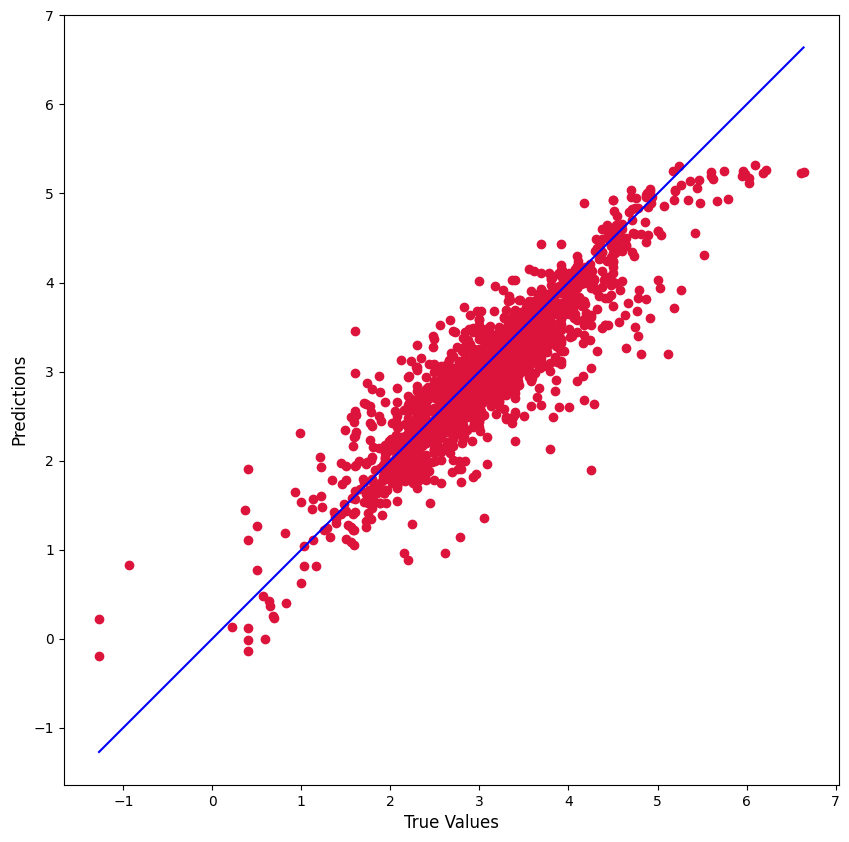

0.790828124479181


In [57]:
plot_pred_vs_true(ln_p_h, ln_p_hat)
print(r2_score(ln_p_h, ln_p_hat))

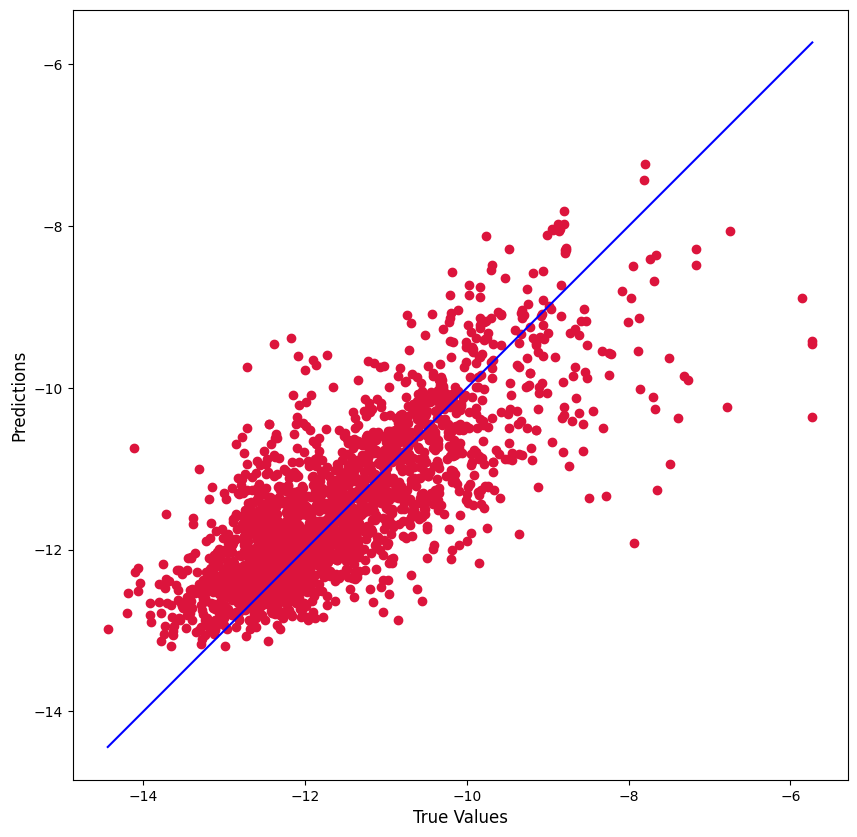

0.6072717795549787


In [58]:
plot_pred_vs_true(ln_q_h, ln_q_hat)
print(r2_score(ln_q_h, ln_q_hat))

## R2 Score from embeddings

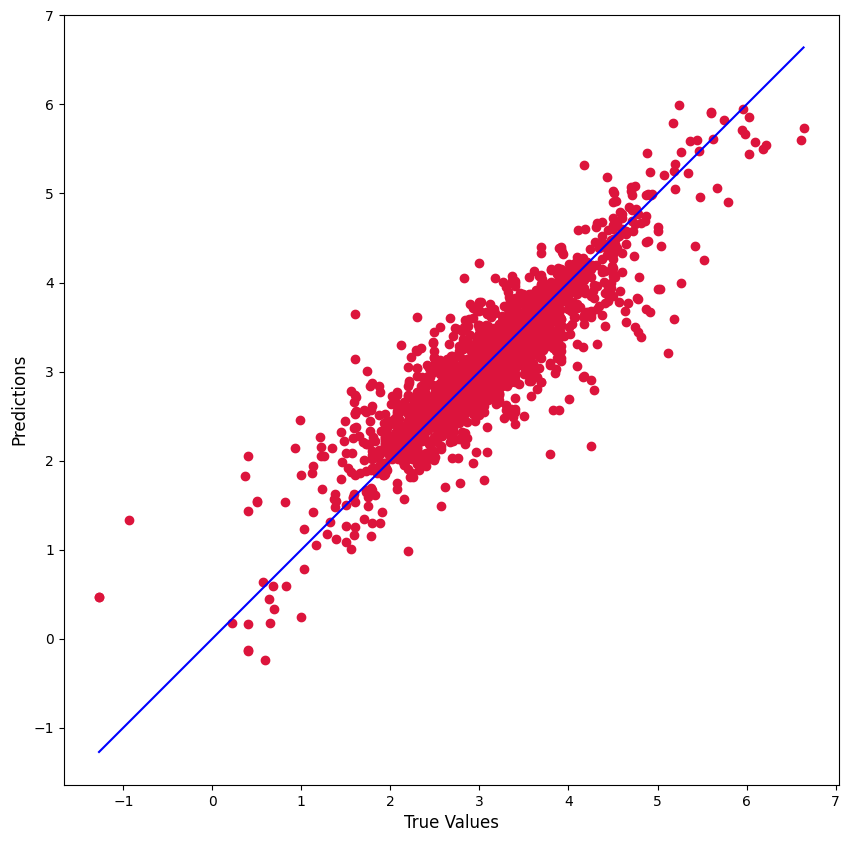

0.7915751431184144


In [60]:
plot_pred_vs_true(ln_p_h, ln_p_hat_embedding)
print(r2_score(ln_p_h, ln_p_hat_embedding))

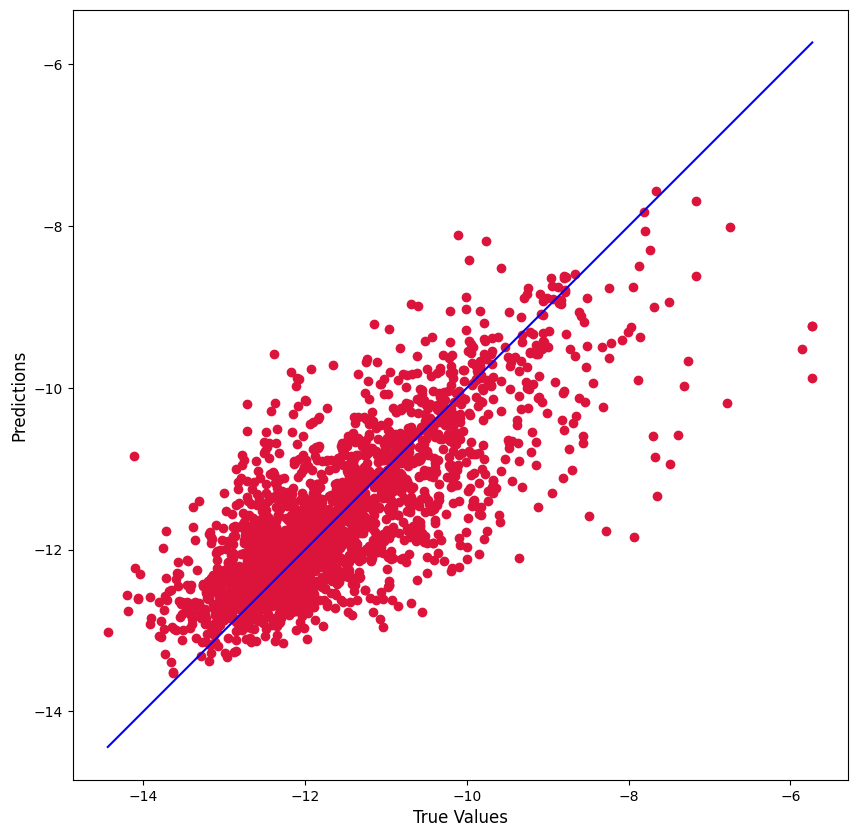

0.5980983472981116


In [61]:
plot_pred_vs_true(ln_q_h, ln_q_hat_embedding)
print(r2_score(ln_q_h, ln_q_hat_embedding))

# Binned Plots

In [66]:
import statsmodels.api as sm # get full stats on regressions

def binned_ols(df, x, y, n_bins, plot=True, plot_title='', plot_ax=None, add_trendline=False, **plt_kwargs):
    # A visual form of de-noising: bin explanatory variable first, 
    # then take means-per-bin of variable to be explaioned, then
    # regress/plot 
    x_bin = x + '_bin'
    df[x_bin] = pd.qcut(df[x], n_bins)

    tmp = df.groupby(x_bin).agg({
        x: 'mean',
        y: 'mean'
    })

    if plot:
        tmp.plot(
            x=x, 
            y=y,
            figsize=(10, 6),
            title=plot_title,
            ax=plot_ax,
            legend=False,
            **plt_kwargs
        )
        if add_trendline:
            z = np.polyfit(tmp[x], tmp[y], 1)
            p = np.poly1d(z)
            plt.plot(tmp[x], p(tmp[x]), color="dimgrey", linewidth=1, linestyle="--")

    del df[x_bin]
    mdl = sm.OLS(tmp[y], tmp[x])
    res = mdl.fit()
    return res

In [40]:
df = embed_obj_dml_data.data

"Naive" elasticity estimated to be -3.569232569714097


/usr/local/lib/python3.11/dist-packages/scipy/stats/_stats_py.py:1806: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=15
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                   ln_q   R-squared (uncentered):                   0.942
Model:                            OLS   Adj. R-squared (uncentered):              0.938
Method:                 Least Squares   F-statistic:                              228.2
Date:                Fri, 22 Sep 2023   Prob (F-statistic):                    4.64e-10
Time:                        15:34:53   Log-Likelihood:                         -36.705
No. Observations:                  15   AIC:                                      75.41
Df Residuals:                      14   BIC:                                      76.12
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
ln_p          -3.5692      0.236    -15.105      0.000      -4.076      -3.062
==============================================================================
Omnibus:                        1.499   Durbin-Watson:                   0.191
Prob(Omnibus):                  0.473   Jarque-Bera (JB):                0.185
Skew:                          -0.047   Prob(JB):                        0.912
Kurtosis:                       3.535   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

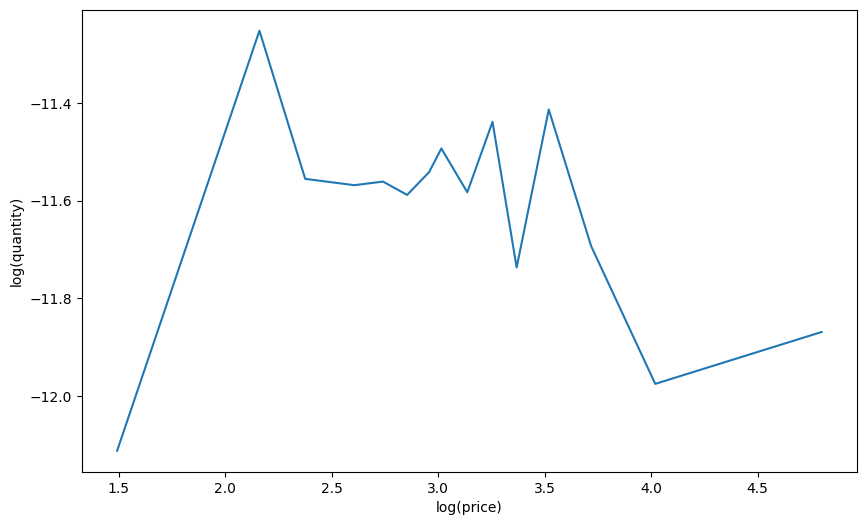

In [67]:
ols_fit = binned_ols(
    df,
    x='ln_p',
    y='ln_q',
    n_bins=15,
    # plot_title='Relationship between ln p and ln q (validation sample)'
)
plt.gca().set(
    xlabel='log(price)',
    ylabel='log(quantity)',    
)
print(f'"Naive" elasticity estimated to be {ols_fit.params["ln_p"]}')
ols_fit.summary()

In [42]:
df['d_ln_p'] = df['ln_p'] - df['ln_p'].mean()
df['d_ln_q'] = df['ln_q'] - df['ln_q'].mean()

In [48]:
df['d_ln_p_res'] = df['ln_p'] - ln_p_hat
df['d_ln_q_res'] = df['ln_q'] - ln_q_hat

"Naive" elasticity estimated to be -0.044178175239427346


/usr/local/lib/python3.11/dist-packages/scipy/stats/_stats_py.py:1806: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=15
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                 d_ln_q   R-squared (uncentered):                   0.025
Model:                            OLS   Adj. R-squared (uncentered):             -0.045
Method:                 Least Squares   F-statistic:                             0.3570
Date:                Fri, 22 Sep 2023   Prob (F-statistic):                       0.560
Time:                        15:34:59   Log-Likelihood:                          1.9673
No. Observations:                  15   AIC:                                     -1.935
Df Residuals:                      14   BIC:                                     -1.227
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
d_ln_p        -0.0442      0.074     -0.598      0.560      -0.203       0.114
==============================================================================
Omnibus:                        6.309   Durbin-Watson:                   1.880
Prob(Omnibus):                  0.043   Jarque-Bera (JB):                3.250
Skew:                          -1.022   Prob(JB):                        0.197
Kurtosis:                       4.010   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

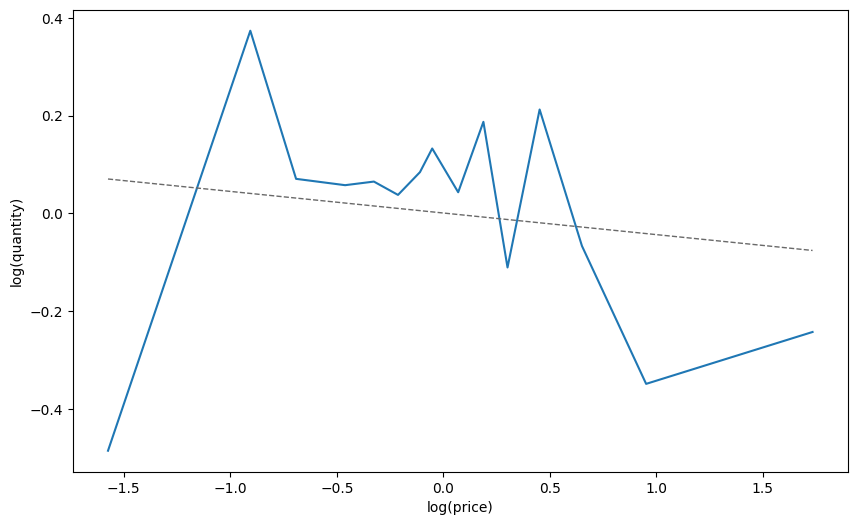

In [68]:
import matplotlib.pyplot as plt

plt.gca().set(
    xlabel='log(price)',
    ylabel='log(quantity)',    
)
# plt.gca().axvline(0, color='k', linestyle=':')
# plt.gca().axhline(0, color='k', linestyle=':')

ols_fit = binned_ols(
    df,
    x='d_ln_p',
    y='d_ln_q',
    n_bins=15,
    add_trendline=True,
    # plot_title='Relationship between mean centered ln p and ln q (holdout sample)',
    plot_ax=plt.gca(),
)
plt.gca().set(
    xlabel='log(price)',
    ylabel='log(quantity)',    
)
#plt.gca().axvline(0, color='k', linestyle=':')
#plt.gca().axhline(0, color='k', linestyle=':')

print(f'"Naive" elasticity estimated to be {ols_fit.params["d_ln_p"]}')
ols_fit.summary()

"Naive" elasticity estimated to be -0.22454945594803172


<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:             d_ln_q_res   R-squared (uncentered):                   0.272
Model:                            OLS   Adj. R-squared (uncentered):              0.234
Method:                 Least Squares   F-statistic:                              7.110
Date:                Fri, 22 Sep 2023   Prob (F-statistic):                      0.0153
Time:                        15:37:05   Log-Likelihood:                          12.647
No. Observations:                  20   AIC:                                     -23.29
Df Residuals:                      19   BIC:                                     -22.30
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
d_ln_p_res    -0.2245      0.084     -2.666      0.015      -0.401      -0.048
==============================================================================
Omnibus:                        1.573   Durbin-Watson:                   0.494
Prob(Omnibus):                  0.456   Jarque-Bera (JB):                1.085
Skew:                           0.291   Prob(JB):                        0.581
Kurtosis:                       2.019   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

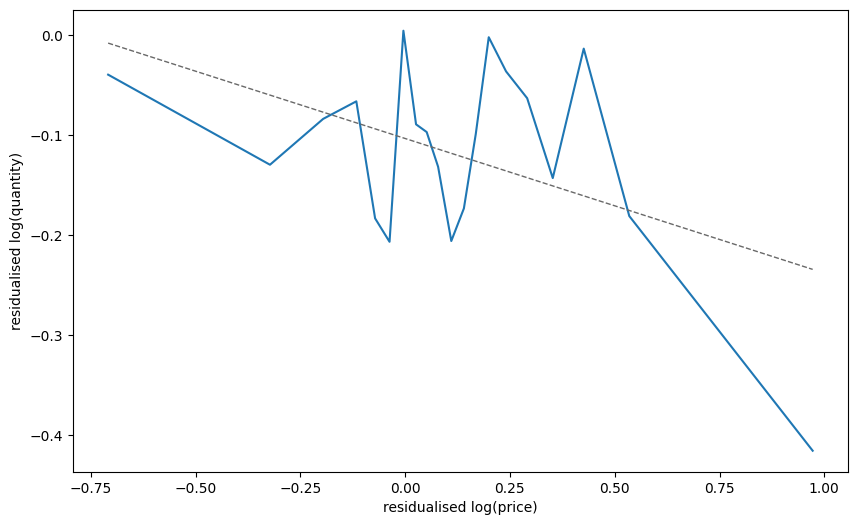

In [69]:
plt.gca().set(
    xlabel='residualised log(price)',
    ylabel='residualised log(quantity)',    
)
# plt.gca().axvline(0, color='k', linestyle=':')
# plt.gca().axhline(0, color='k', linestyle=':')

res_fit = binned_ols(
    df,
    x='d_ln_p_res',
    y='d_ln_q_res',
    n_bins=20,
    add_trendline=True,
    # plot_title='Relationship between residualised ln p and ln q (holdout sample)',
    plot_ax=plt.gca(),
)

plt.gca().set(
    xlabel='residualised log(price)',
    ylabel='residualised log(quantity)',    
)
print(f'"Naive" elasticity estimated to be {res_fit.params["d_ln_p_res"]}')
res_fit.summary()

"Naive" elasticity estimated to be -0.044178175239427346


/usr/local/lib/python3.11/dist-packages/scipy/stats/_stats_py.py:1806: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=15
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                 d_ln_q   R-squared (uncentered):                   0.025
Model:                            OLS   Adj. R-squared (uncentered):             -0.045
Method:                 Least Squares   F-statistic:                             0.3570
Date:                Fri, 22 Sep 2023   Prob (F-statistic):                       0.560
Time:                        15:37:35   Log-Likelihood:                          1.9673
No. Observations:                  15   AIC:                                     -1.935
Df Residuals:                      14   BIC:                                     -1.227
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
d_ln_p        -0.0442      0.074     -0.598      0.560      -0.203       0.114
==============================================================================
Omnibus:                        6.309   Durbin-Watson:                   1.880
Prob(Omnibus):                  0.043   Jarque-Bera (JB):                3.250
Skew:                          -1.022   Prob(JB):                        0.197
Kurtosis:                       4.010   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

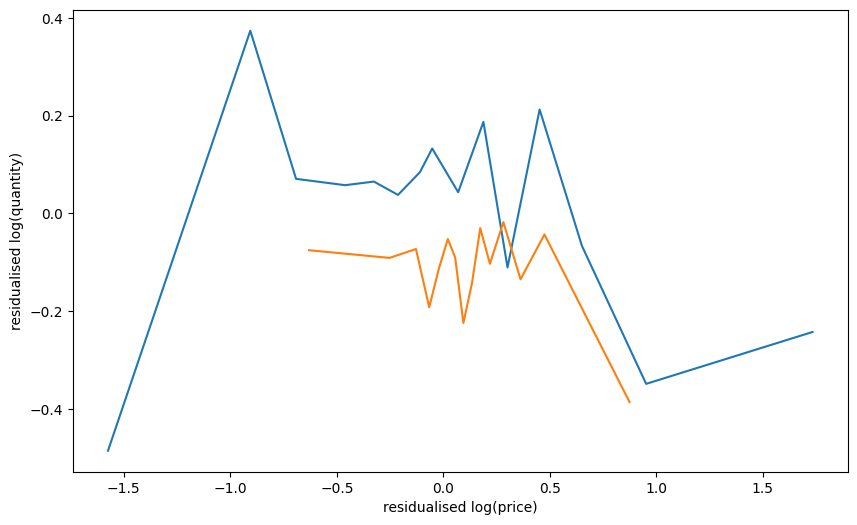

In [70]:
plt.gca().set(
    xlabel='log(price)',
    ylabel='log(quantity)',    
)
# plt.gca().axvline(0, color='k', linestyle=':')
# plt.gca().axhline(0, color='k', linestyle=':')

ols_fit = binned_ols(
    df,
    x='d_ln_p',
    y='d_ln_q',
    n_bins=15,
    plot_ax=plt.gca(),
)
plt.gca().set(
    xlabel='log(price)',
    ylabel='log(quantity)',    
)
# plt.gca().axvline(0, color='k', linestyle=':')
# plt.gca().axhline(0, color='k', linestyle=':')

res_fit = binned_ols(
    df,
    x='d_ln_p_res',
    y='d_ln_q_res',
    n_bins=15,
    #plot_title='Relationship between ln p and ln q',
    plot_ax=plt.gca(),
)

plt.gca().set(
    xlabel='residualised log(price)',
    ylabel='residualised log(quantity)',    
)
print(f'"Naive" elasticity estimated to be {ols_fit.params["d_ln_p"]}')
ols_fit.summary()

In [93]:
df["ln_q_hat"] = ln_q_hat
df["ln_p_hat"] = ln_p_hat

df.to_csv("presentation_data_plots.csv")

In [94]:
df

,ln_q,ln_p,0,1,2,3,4,5,6,7,...,1532,1533,1534,1535,d_ln_p,d_ln_q,d_ln_p_res,d_ln_q_res,ln_q_hat,ln_p_hat
0,-11.664556,4.499699,0.000000,0.0,0.0,0.913574,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.257568,1.433122,-0.038255,0.034855,0.171382,-11.835938,4.464844
1,-12.542306,3.086030,0.146973,0.0,0.0,0.682617,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.019454,-0.916005,0.015718,0.145194,-12.687500,3.070312
2,-12.386835,2.995232,0.000000,0.0,0.0,0.743164,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.030716,-0.071344,-0.760535,-0.178596,-0.332148,-12.054688,3.173828
3,-12.783200,2.832625,0.308594,0.0,0.0,0.716309,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.014542,0.000000,-0.233951,-1.156900,-0.061906,-1.103513,-11.679688,2.894531
4,-10.902427,3.295466,0.000000,0.0,0.0,0.773438,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.228890,0.723874,0.459529,-0.035239,-10.867188,2.835938
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2296,-10.969870,2.922086,0.263428,0.0,0.0,0.727539,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.000000,-0.144490,0.656431,0.150601,1.405130,-12.375000,2.771484
2297,-11.284782,2.707383,0.337891,0.0,0.0,0.673828,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.092224,0.000000,-0.359193,0.341518,-0.026992,0.488655,-11.773438,2.734375
2298,-13.381521,2.995232,0.340820,0.0,0.0,0.727051,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.020767,0.000000,-0.071344,-1.755221,0.190545,-1.772146,-11.609375,2.804688
2299,-10.879386,3.157851,0.069092,0.0,0.0,0.609375,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.091275,0.746915,0.132461,-0.504386,-10.375000,3.025391


# Regressions

## Baseline Regression

In [63]:
mdl = sm.OLS(df["ln_q"], sm.add_constant(df["ln_p"]))
res = mdl.fit()
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   ln_q   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.722
Date:                Fri, 22 Sep 2023   Prob (F-statistic):              0.190
Time:                        15:28:21   Log-Likelihood:                -3673.4
No. Observations:                2301   AIC:                             7351.
Df Residuals:                    2299   BIC:                             7362.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -11.5002      0.099   -115.861      0.000     -11.695     -11.306
ln_p          -0.0411      0.031     -1.312      0.190      -0.103       0.020
==============================================================================
Omnibus:                      375.404   Durbin-Watson:                   2.054
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              652.242
Skew:                           1.045   Prob(JB):                    2.33e-142
Kurtosis:                       4.561   Cond. No.                         13.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [64]:
mdl = sm.OLS(df["ln_q"], df["ln_p"])
res = mdl.fit()
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                   ln_q   R-squared (uncentered):                   0.929
Model:                            OLS   Adj. R-squared (uncentered):              0.929
Method:                 Least Squares   F-statistic:                          2.991e+04
Date:                Fri, 22 Sep 2023   Prob (F-statistic):                        0.00
Time:                        15:28:55   Log-Likelihood:                         -5885.4
No. Observations:                2301   AIC:                                  1.177e+04
Df Residuals:                    2300   BIC:                                  1.178e+04
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
ln_p          -3.5552      0.021   -172.951      0.000      -3.595      -3.515
==============================================================================
Omnibus:                      108.663   Durbin-Watson:                   1.928
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              355.959
Skew:                          -0.102   Prob(JB):                     5.06e-78
Kurtosis:                       4.916   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Residualized Regression

In [62]:
mdl = sm.OLS(df["d_ln_q_res"], sm.add_constant(df["d_ln_p_res"]))
res = mdl.fit()
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             d_ln_q_res   R-squared:                       0.004
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     9.103
Date:                Fri, 22 Sep 2023   Prob (F-statistic):            0.00258
Time:                        15:27:40   Log-Likelihood:                -2565.6
No. Observations:                2301   AIC:                             5135.
Df Residuals:                    2299   BIC:                             5147.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.1035      0.016     -6.435      0.000      -0.135      -0.072
d_ln_p_res    -0.1335      0.044     -3.017      0.003      -0.220      -0.047
==============================================================================
Omnibus:                      346.144   Durbin-Watson:                   1.996
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1404.329
Skew:                           0.684   Prob(JB):                    1.13e-305
Kurtosis:                       6.574   Cond. No.                         2.91
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [65]:
mdl = sm.OLS(df["d_ln_q_res"], df["d_ln_p_res"])
res = mdl.fit()
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:             d_ln_q_res   R-squared (uncentered):                   0.011
Model:                            OLS   Adj. R-squared (uncentered):              0.011
Method:                 Least Squares   F-statistic:                              25.78
Date:                Fri, 22 Sep 2023   Prob (F-statistic):                    4.14e-07
Time:                        15:29:33   Log-Likelihood:                         -2586.1
No. Observations:                2301   AIC:                                      5174.
Df Residuals:                    2300   BIC:                                      5180.
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
d_ln_p_res    -0.2168      0.043     -5.077      0.000      -0.301      -0.133
==============================================================================
Omnibus:                      344.681   Durbin-Watson:                   1.969
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1404.648
Skew:                           0.680   Prob(JB):                    9.65e-306
Kurtosis:                       6.578   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""